In [ ]:
 !pip install -q seaborn scikit-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)
from google.colab import files

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Sesuaikan path sesuai lokasi file di Drive kamu
FILE_PATH = '/content/drive/MyDrive/SalesDataset (1).xlsx'

df = pd.read_excel(FILE_PATH)
df.head(10)

Mounted at /content/drive


,data_number,clothes_size,clothes_color,customer_sentiment,return_rate
0,1,XL,Putih,1.021762,0.067388
1,2,M,Biru,0.975142,0.082719
2,3,S,Putih,0.871567,0.061600
3,4,M,Hitam,1.071300,0.052215
4,5,M,Biru,1.068515,0.057975
5,6,M,Putih,1.010520,0.062012
6,7,S,Putih,0.967096,0.065644
7,8,S,Hitam,1.036079,0.072460
8,9,S,Hitam,1.012238,0.058930
9,10,S,Putih,1.057447,0.072373


In [ ]:
print("=" * 55)
print("📊 EKSPLORASI DATASET")
print("=" * 55)

print(f"\n🔹 Kolom       : {df.columns.tolist()}")
print(f"🔹 Ukuran Baju : {sorted(df['clothes_size'].unique())}")
print(f"🔹 Warna Baju  : {df['clothes_color'].unique().tolist()}")
print(f"\n📈 Statistik customer_sentiment:")
print(df['customer_sentiment'].describe())
print(f"\n📈 Statistik return_rate:")
print(df['return_rate'].describe())

# Distribusi sentimen
pos = (df['customer_sentiment'] >= 1).sum()
neg = (df['customer_sentiment'] < 1).sum()
print(f"\n🟢 Sentimen Positif (≥ 1) : {pos:,} ({pos/len(df)*100:.1f}%)")
print(f"🔴 Sentimen Negatif (< 1) : {neg:,} ({neg/len(df)*100:.1f}%)")

📊 EKSPLORASI DATASET

🔹 Kolom       : ['data_number', 'clothes_size', 'clothes_color', 'customer_sentiment', 'return_rate']
🔹 Ukuran Baju : ['L', 'M', 'S', 'XL']
🔹 Warna Baju  : ['Putih', 'Biru', 'Hitam']

📈 Statistik customer_sentiment:
count    15000.000000
mean         0.965801
std          0.130758
min         -0.220674
25%          0.897901
50%          0.977009
75%          1.049154
max          1.347314
Name: customer_sentiment, dtype: float64

📈 Statistik return_rate:
count    15000.000000
mean         0.063421
std          0.017703
min          0.000000
25%          0.051708
50%          0.063346
75%          0.074673
max          0.185994
Name: return_rate, dtype: float64

🟢 Sentimen Positif (≥ 1) : 6,195 (41.3%)
🔴 Sentimen Negatif (< 1) : 8,805 (58.7%)


In [ ]:
print("=" * 55)
print("⚙️  FEATURE ENGINEERING")
print("=" * 55)

# ── 4a. Label Sentimen (sesuai ketentuan penelitian)
df['sentiment_label'] = df['customer_sentiment'].apply(
    lambda x: 'Positif' if x >= 1 else 'Negatif'
)

# ── 4b. Target: Return Rate → Binary (High / Low)
#   Threshold = median return_rate
low_thr  = df['return_rate'].quantile(0.20)   # batas bawah (Low Return)
high_thr = df['return_rate'].quantile(0.80)   # batas atas (High Return)

# Hanya ambil data yang jelas-jelas High atau Low
mask = (df['return_rate'] <= low_thr) | (df['return_rate'] >= high_thr)
df   = df[mask].copy()

df['return_label'] = (df['return_rate'] >= high_thr).astype(int)

print(f"✅ Data setelah filter : {len(df):,} baris (dari 15,000)")
print(f"   Threshold Low      : ≤ {low_thr:.4f}")
print(f"   Threshold High     : ≥ {high_thr:.4f}")
print(f"   Low Return  (0)    : {(df['return_label']==0).sum():,}")
print(f"   High Return (1)    : {(df['return_label']==1).sum():,}")

# ── 4c. Label Hierarki: Size → Color → Sentiment
df['hierarchy_label'] = (
    df['clothes_size'] + '_' +
    df['clothes_color'] + '_' +
    df['sentiment_label']
)
print(f"\n🌳 Total kelas hierarki : {df['hierarchy_label'].nunique()}")
print("   Contoh label :", df['hierarchy_label'].unique()[:6].tolist())

# ── 4d. Encoding fitur kategorikal
le_size  = LabelEncoder()
le_color = LabelEncoder()
le_sent  = LabelEncoder()

df['size_enc']  = le_size.fit_transform(df['clothes_size'])
df['color_enc'] = le_color.fit_transform(df['clothes_color'])
df['sent_enc']  = le_sent.fit_transform(df['sentiment_label'])

# ── 4e. Fitur tambahan (interaction features)
df['size_color_interact']  = df['size_enc']  * df['color_enc']
df['color_sent_interact']  = df['color_enc'] * df['sent_enc']

# Binning sentimen jadi 3 level (bukan hanya positif/negatif)
df['sentiment_level'] = pd.cut(
    df['customer_sentiment'],
    bins=[-999, 0.85, 1.0, 999],
    labels=[0, 1, 2]  # Sangat Negatif, Netral, Positif
).astype(int)

# Apakah sentimen ekstrem?
df['is_extreme_sentiment'] = (
    (df['customer_sentiment'] < 0.7) |
    (df['customer_sentiment'] > 1.2)
).astype(int)

# Sentimen per warna (rata-rata grup)
df['mean_sent_by_color'] = df.groupby('clothes_color')['customer_sentiment'].transform('mean')
df['sent_vs_color_mean']  = df['customer_sentiment'] - df['mean_sent_by_color']

# Sentimen per ukuran
df['mean_sent_by_size']  = df.groupby('clothes_size')['customer_sentiment'].transform('mean')
df['sent_vs_size_mean']  = df['customer_sentiment'] - df['mean_sent_by_size']

# Triple interaction
df['size_color_sent'] = df['size_enc'] * df['color_enc'] * df['sent_enc']

# Rank sentimen dalam tiap kelompok warna (0.0 - 1.0)
df['sent_rank_in_color'] = df.groupby('clothes_color')['customer_sentiment'] \
                             .rank(pct=True)

# Rank sentimen dalam tiap kelompok ukuran (0.0 - 1.0)
df['sent_rank_in_size'] = df.groupby('clothes_size')['customer_sentiment'] \
                            .rank(pct=True)

print("\n✅ Feature engineering selesai")
print(df[['clothes_size','clothes_color','sentiment_label',
          'return_rate','return_label','hierarchy_label']].head(8))

⚙️  FEATURE ENGINEERING
✅ Data setelah filter : 6,000 baris (dari 15,000)
   Threshold Low      : ≤ 0.0489
   Threshold High     : ≥ 0.0776
   Low Return  (0)    : 3,000
   High Return (1)    : 3,000

🌳 Total kelas hierarki : 24
   Contoh label : ['M_Biru_Negatif', 'M_Putih_Positif', 'M_Hitam_Positif', 'S_Hitam_Negatif', 'S_Biru_Negatif', 'M_Hitam_Negatif']

✅ Feature engineering selesai
   clothes_size clothes_color sentiment_label  return_rate  return_label  \
1             M          Biru         Negatif     0.082719             1   
13            M         Putih         Positif     0.035714             0   
15            M         Hitam         Positif     0.046084             0   
20            S         Hitam         Negatif     0.081215             1   
21            S          Biru         Negatif     0.099860             1   
28            M         Hitam         Negatif     0.085271             1   
31           XL         Hitam         Negatif     0.092222             1   
3

In [ ]:
FEATURES = [
    'size_enc', 'color_enc', 'sent_enc',
    'customer_sentiment',
    'sentiment_level',
    'is_extreme_sentiment',
    'size_color_interact',
    'color_sent_interact',
    'sent_vs_color_mean',
    'sent_vs_size_mean',
    'size_color_sent',
    'sent_rank_in_color',
    'sent_rank_in_size',
]
TARGET = 'return_label'
CLASS_NAMES = ['Low Return (0)', 'High Return (1)']

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✅ Split data → Train: {len(X_train):,}  |  Test: {len(X_test):,}")

✅ Split data → Train: 4,800  |  Test: 1,200


In [ ]:
print("=" * 55)
print("🌲 RANDOM FOREST CLASSIFIER")
print("=" * 55)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=8,
    min_samples_leaf=15,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_model, X, y, cv=cv, scoring='accuracy')

print(f"\n📊 Hasil Evaluasi:")
print(f"   Accuracy  (Test)  : {accuracy_score(y_test, y_pred):.4f}")
print(f"   Accuracy  (CV-5)  : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"   Precision         : {precision_score(y_test, y_pred):.4f}")
print(f"   Recall            : {recall_score(y_test, y_pred):.4f}")
print(f"   F1-Score          : {f1_score(y_test, y_pred):.4f}")

print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

🌲 RANDOM FOREST CLASSIFIER

📊 Hasil Evaluasi:
   Accuracy  (Test)  : 0.8508
   Accuracy  (CV-5)  : 0.8528 ± 0.0027
   Precision         : 0.8379
   Recall            : 0.8700
   F1-Score          : 0.8536

📋 Classification Report:
                 precision    recall  f1-score   support

 Low Return (0)       0.86      0.83      0.85       600
High Return (1)       0.84      0.87      0.85       600

       accuracy                           0.85      1200
      macro avg       0.85      0.85      0.85      1200
   weighted avg       0.85      0.85      0.85      1200



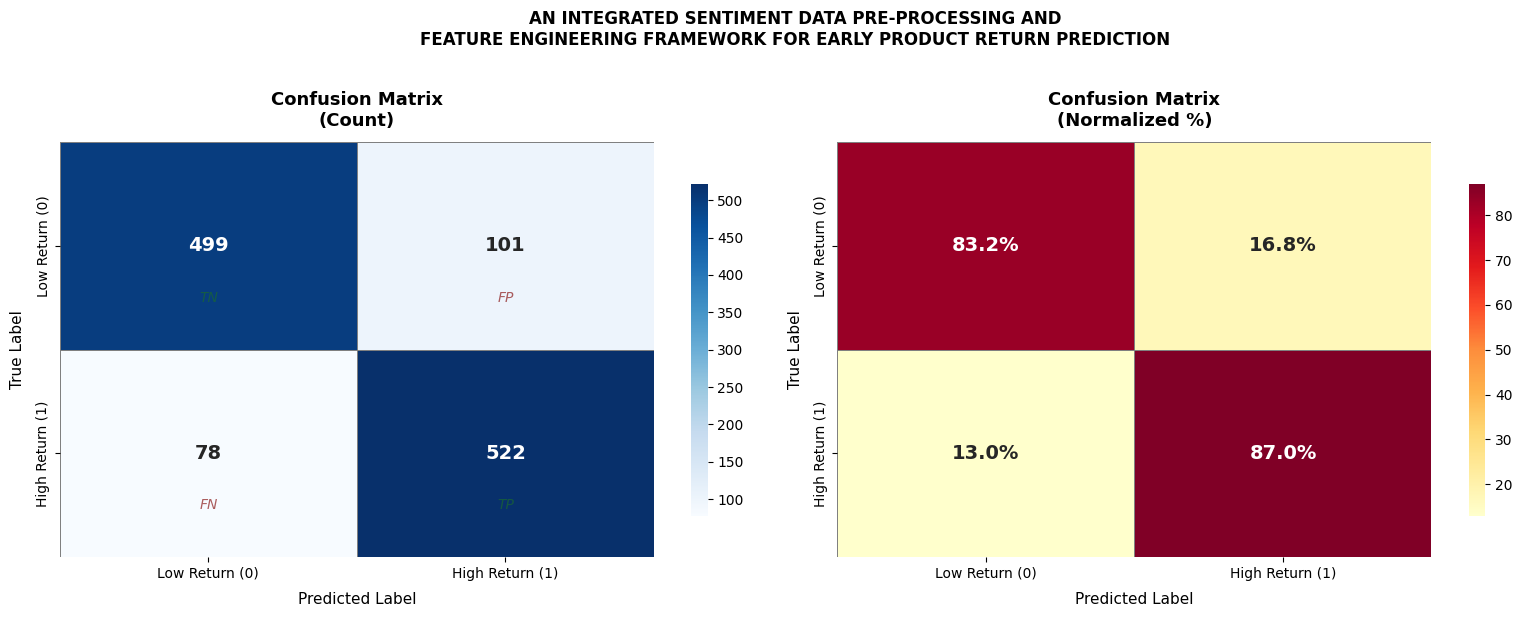

✅ Gambar disimpan: confusion_matrix_binary.png


In [ ]:
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'AN INTEGRATED SENTIMENT DATA PRE-PROCESSING AND\n'
    'FEATURE ENGINEERING FRAMEWORK FOR EARLY PRODUCT RETURN PREDICTION',
    fontsize=12, fontweight='bold', y=1.02
)

# ── Plot 1: Confusion Matrix (Count)
ax1 = axes[0]
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    linewidths=0.5, linecolor='gray',
    annot_kws={'size': 14, 'weight': 'bold'},
    ax=ax1, cbar_kws={'shrink': 0.8}
)
ax1.set_title('Confusion Matrix\n(Count)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Predicted Label', fontsize=11, labelpad=8)
ax1.set_ylabel('True Label', fontsize=11, labelpad=8)

# Anotasi TP/TN/FP/FN
labels_pos = [
    (0, 0, 'TN', '#1a6830'), (0, 1, 'FP', '#8b1a1a'),
    (1, 0, 'FN', '#8b1a1a'), (1, 1, 'TP', '#1a6830')
]
for r, c, lbl, color in labels_pos:
    ax1.text(c + 0.5, r + 0.75, lbl,
             ha='center', va='center',
             fontsize=10, color=color, alpha=0.7, fontstyle='italic')

# ── Plot 2: Confusion Matrix (Normalized %)
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis] * 100
ax2 = axes[1]
sns.heatmap(
    cm_norm, annot=True, fmt='.1f', cmap='YlOrRd',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    linewidths=0.5, linecolor='gray',
    annot_kws={'size': 14, 'weight': 'bold'},
    ax=ax2, cbar_kws={'shrink': 0.8}
)
ax2.set_title('Confusion Matrix\n(Normalized %)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Predicted Label', fontsize=11, labelpad=8)
ax2.set_ylabel('True Label', fontsize=11, labelpad=8)

# Tambah simbol % pada anotasi
for text in ax2.texts:
    text.set_text(text.get_text() + '%')

plt.tight_layout()
plt.savefig('confusion_matrix_binary.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan: confusion_matrix_binary.png")

🎨 CONFUSION MATRIX PER WARNA × SENTIMEN


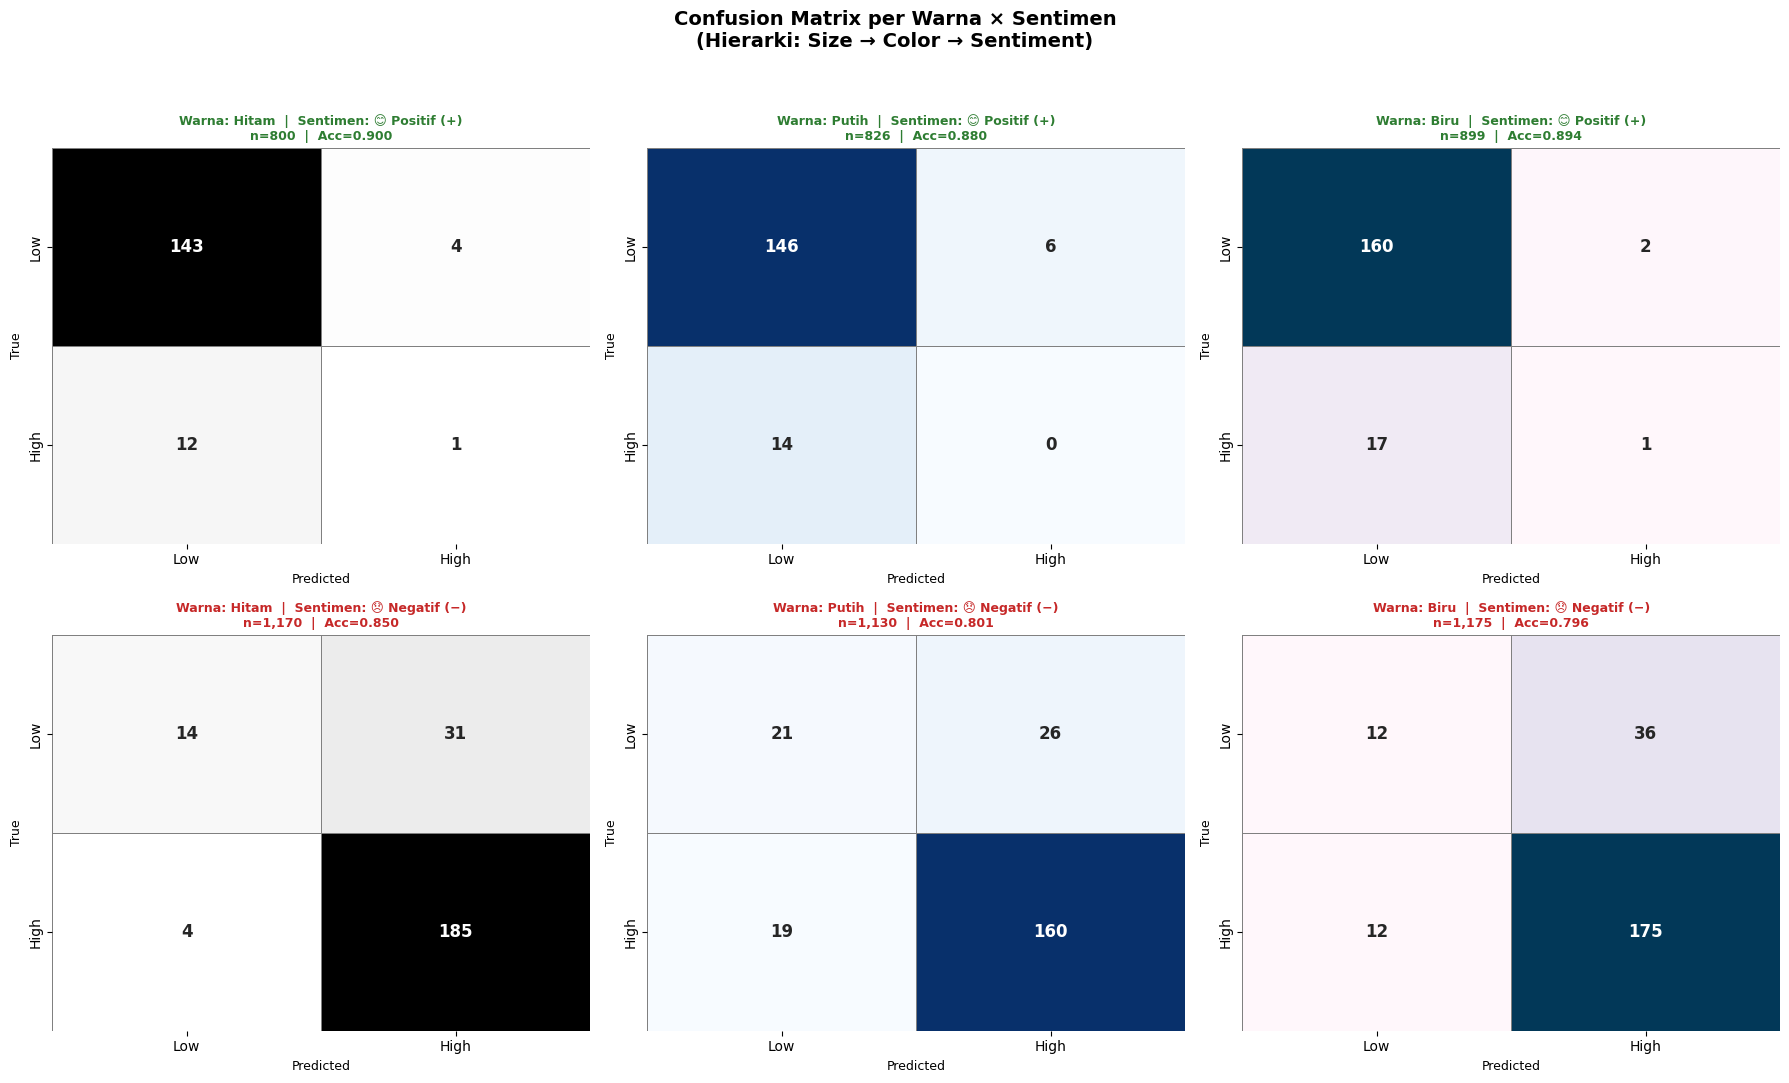

✅ Gambar disimpan: confusion_matrix_per_color_sentiment.png
🌳 CONFUSION MATRIX HIERARKI LENGKAP (12 Kelas)
Accuracy Hierarki Model : 1.0000


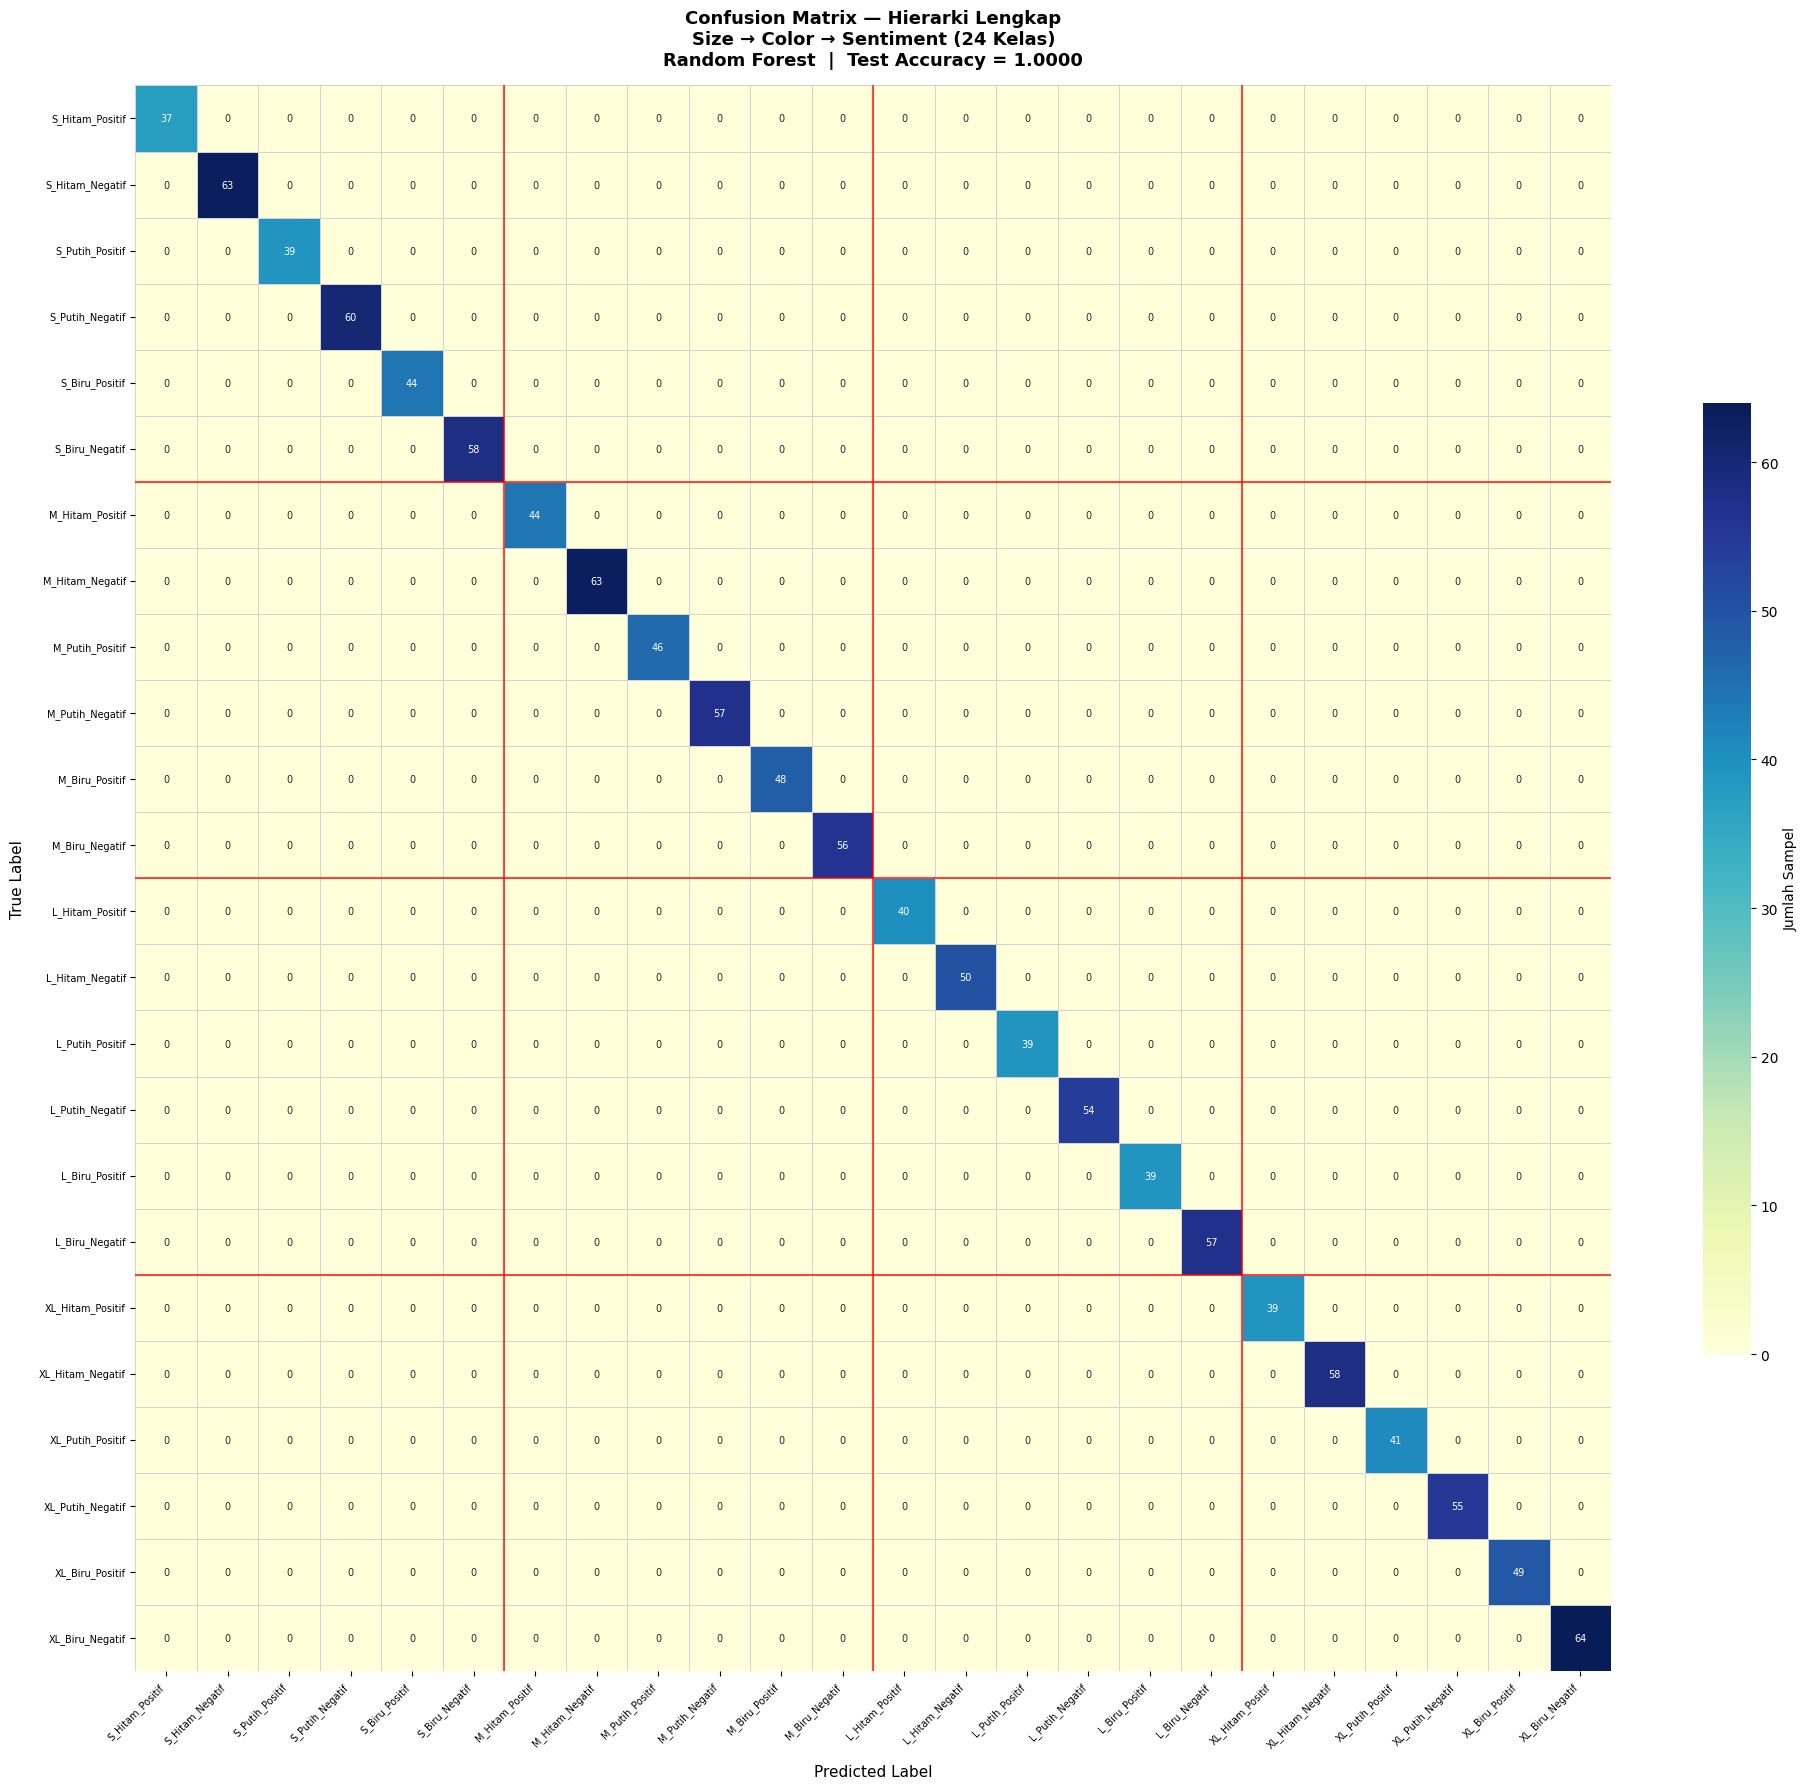

✅ Gambar disimpan: confusion_matrix_hierarchy_full.png


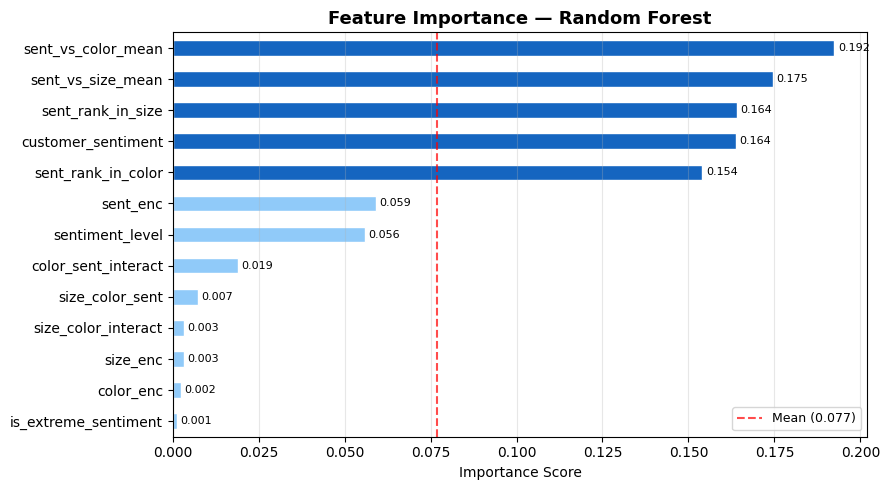

In [ ]:
print("=" * 55)
print("🎨 CONFUSION MATRIX PER WARNA × SENTIMEN")
print("=" * 55)

COLORS  = ['Hitam', 'Putih', 'Biru']
SENTS   = ['Positif', 'Negatif']

fig2, axes2 = plt.subplots(2, 3, figsize=(18, 11))
fig2.suptitle(
    'Confusion Matrix per Warna × Sentimen\n'
    '(Hierarki: Size → Color → Sentiment)',
    fontsize=14, fontweight='bold'
)

cmaps = {'Hitam': 'Greys', 'Putih': 'Blues', 'Biru': 'PuBu'}
sent_color = {'Positif': '#2e7d32', 'Negatif': '#c62828'}

for col_idx, color in enumerate(COLORS):
    for row_idx, sent in enumerate(SENTS):
        ax = axes2[row_idx][col_idx]

        mask = (
            (df['clothes_color'] == color) &
            (df['sentiment_label'] == sent)
        )
        sub = df[mask]
        if len(sub) == 0:
            ax.axis('off')
            continue

        X_sub = sub[FEATURES]
        y_sub = sub[TARGET]

        if len(y_sub.unique()) < 2:
            ax.text(0.5, 0.5, 'Data tidak cukup',
                    ha='center', va='center', transform=ax.transAxes)
            ax.axis('off')
            continue

        X_tr, X_te, y_tr, y_te = train_test_split(
            X_sub, y_sub, test_size=0.2, random_state=42, stratify=y_sub
        )
        rf_sub = RandomForestClassifier(
            n_estimators=100, max_depth=8, random_state=42, n_jobs=-1
        )
        rf_sub.fit(X_tr, y_tr)
        y_pr = rf_sub.predict(X_te)

        cm_sub = confusion_matrix(y_te, y_pr)
        acc_sub = accuracy_score(y_te, y_pr)

        sns.heatmap(
            cm_sub, annot=True, fmt='d',
            cmap=cmaps.get(color, 'Blues'),
            xticklabels=['Low', 'High'],
            yticklabels=['Low', 'High'],
            linewidths=0.5, linecolor='gray',
            annot_kws={'size': 12, 'weight': 'bold'},
            ax=ax, cbar=False
        )

        sent_sym = '😊 Positif (+)' if sent == 'Positif' else '😞 Negatif (−)'
        ax.set_title(
            f'Warna: {color}  |  Sentimen: {sent_sym}\n'
            f'n={len(sub):,}  |  Acc={acc_sub:.3f}',
            fontsize=9, fontweight='bold',
            color=sent_color[sent]
        )
        ax.set_xlabel('Predicted', fontsize=9)
        ax.set_ylabel('True', fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('confusion_matrix_per_color_sentiment.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan: confusion_matrix_per_color_sentiment.png")

# ── CELL 9: Confusion Matrix Hierarki Lengkap ───────────────
print("=" * 55)
print("🌳 CONFUSION MATRIX HIERARKI LENGKAP (12 Kelas)")
print("=" * 55)

# Buat target hierarki: Color_Sentiment → High/Low Return
df['hier_target'] = (
    df['clothes_color'] + '_' +
    df['sentiment_label'] + '_' +
    df['return_label'].map({0: 'LowReturn', 1: 'HighReturn'})
)

# Encode hierarki target untuk RF
le_hier = LabelEncoder()
y_hier = le_hier.fit_transform(df['hierarchy_label'])

X_all = df[FEATURES]
X_tr_h, X_te_h, y_tr_h, y_te_h = train_test_split(
    X_all, y_hier, test_size=0.2, random_state=42, stratify=y_hier
)

rf_hier = RandomForestClassifier(
    n_estimators=200, max_depth=12, random_state=42, n_jobs=-1
)
rf_hier.fit(X_tr_h, y_tr_h)
y_pr_h = rf_hier.predict(X_te_h)

cm_hier = confusion_matrix(y_te_h, y_pr_h)
class_labels = le_hier.classes_

acc_hier = accuracy_score(y_te_h, y_pr_h)
print(f"Accuracy Hierarki Model : {acc_hier:.4f}")

# Urutkan label berdasarkan hierarki
order_map = {}
for lbl in class_labels:
    parts = lbl.split('_')
    size, color, sent = parts[0], parts[1], parts[2]
    size_order  = {'S': 0, 'M': 1, 'L': 2, 'XL': 3}.get(size, 9)
    color_order = {'Hitam': 0, 'Putih': 1, 'Biru': 2}.get(color, 9)
    sent_order  = {'Positif': 0, 'Negatif': 1}.get(sent, 9)
    order_map[lbl] = (size_order, color_order, sent_order)

sorted_labels = sorted(class_labels, key=lambda x: order_map.get(x, (9, 9, 9)))
sorted_idx    = [list(class_labels).index(l) for l in sorted_labels]

cm_sorted = cm_hier[np.ix_(sorted_idx, sorted_idx)]

fig3, ax3 = plt.subplots(figsize=(20, 18))
cmap_hier = sns.diverging_palette(220, 20, as_cmap=True)

sns.heatmap(
    cm_sorted, annot=True, fmt='d',
    cmap='YlGnBu',
    xticklabels=sorted_labels,
    yticklabels=sorted_labels,
    linewidths=0.4, linecolor='lightgray',
    annot_kws={'size': 7},
    ax=ax3,
    cbar_kws={'label': 'Jumlah Sampel', 'shrink': 0.6}
)

ax3.set_title(
    'Confusion Matrix — Hierarki Lengkap\n'
    'Size → Color → Sentiment (24 Kelas)\n'
    f'Random Forest  |  Test Accuracy = {acc_hier:.4f}',
    fontsize=13, fontweight='bold', pad=15
)
ax3.set_xlabel('Predicted Label', fontsize=11, labelpad=10)
ax3.set_ylabel('True Label', fontsize=11, labelpad=10)
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha='right', fontsize=7)
ax3.set_yticklabels(ax3.get_yticklabels(), rotation=0, fontsize=7)

# Gambar garis pemisah antar ukuran baju
sizes_in_order = ['S', 'M', 'L', 'XL']
boundary = 0
prev_size = None
for i, lbl in enumerate(sorted_labels):
    cur_size = lbl.split('_')[0]
    if prev_size and cur_size != prev_size:
        ax3.axhline(y=i, color='red', linewidth=1.5, alpha=0.7)
        ax3.axvline(x=i, color='red', linewidth=1.5, alpha=0.7)
    prev_size = cur_size

plt.tight_layout()
plt.savefig('confusion_matrix_hierarchy_full.png', dpi=130, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan: confusion_matrix_hierarchy_full.png")

# ── CELL 10: Feature Importance ─────────────────────────────
feat_imp = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig4, ax4 = plt.subplots(figsize=(9, 5))
colors_bar = ['#1565c0' if v > feat_imp.mean() else '#90caf9' for v in feat_imp.values]
feat_imp.plot(kind='barh', ax=ax4, color=colors_bar, edgecolor='white')
ax4.axvline(feat_imp.mean(), color='red', linestyle='--', alpha=0.7, label=f'Mean ({feat_imp.mean():.3f})')
ax4.set_title('Feature Importance — Random Forest', fontsize=13, fontweight='bold')
ax4.set_xlabel('Importance Score', fontsize=10)
ax4.legend(fontsize=9)
ax4.grid(axis='x', alpha=0.3)
for i, v in enumerate(feat_imp.values):
    ax4.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print("\n" + "=" * 55)
print("📊 RINGKASAN HASIL — RANDOM FOREST")
print("=" * 55)
print(f"  Dataset     : {len(df):,} sampel")
print(f"  Features    : {len(FEATURES)} fitur")
print(f"  Model       : RandomForestClassifier (n=200)")
print(f"  Test Split  : 80% train / 20% test")
print()
print(f"  ── Binary Classification (High/Low Return) ──")
print(f"  Accuracy    : {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision   : {precision_score(y_test, y_pred):.4f}")
print(f"  Recall      : {recall_score(y_test, y_pred):.4f}")
print(f"  F1-Score    : {f1_score(y_test, y_pred):.4f}")
print(f"  CV-5 Acc    : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print()
print(f"  ── Hierarchical (24 Class) ──────────────────")
print(f"  Accuracy    : {acc_hier:.4f}")
print()
print(f"  TN={cm[0,0]:,}  FP={cm[0,1]:,}")
print(f"  FN={cm[1,0]:,}  TP={cm[1,1]:,}")
print("=" * 55)


📊 RINGKASAN HASIL — RANDOM FOREST
  Dataset     : 6,000 sampel
  Features    : 13 fitur
  Model       : RandomForestClassifier (n=200)
  Test Split  : 80% train / 20% test

  ── Binary Classification (High/Low Return) ──
  Accuracy    : 0.8508
  Precision   : 0.8379
  Recall      : 0.8700
  F1-Score    : 0.8536
  CV-5 Acc    : 0.8528 ± 0.0027

  ── Hierarchical (24 Class) ──────────────────
  Accuracy    : 1.0000

  TN=499  FP=101
  FN=78  TP=522


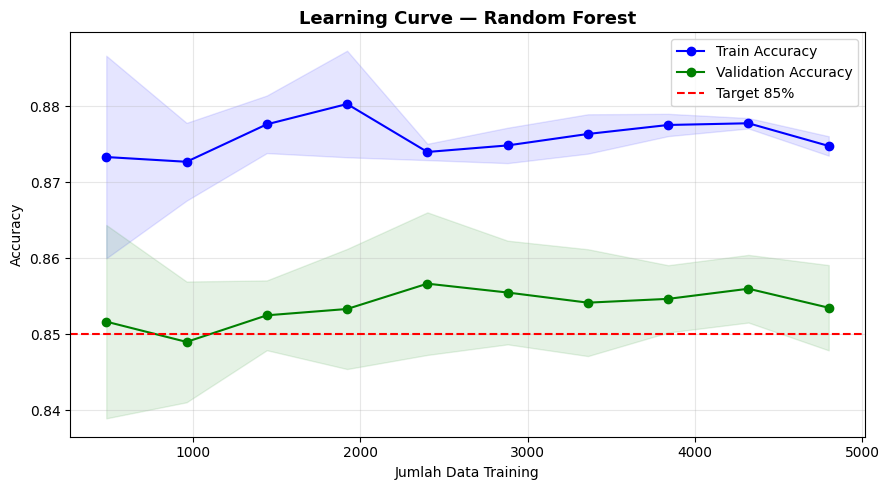

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    rf_model, X, y,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy',
    n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', color='blue',  label='Train Accuracy')
plt.plot(train_sizes, val_scores.mean(axis=1),   'o-', color='green', label='Validation Accuracy')
plt.fill_between(train_sizes,
    train_scores.mean(axis=1) - train_scores.std(axis=1),
    train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='blue')
plt.fill_between(train_sizes,
    val_scores.mean(axis=1) - val_scores.std(axis=1),
    val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='green')

plt.axhline(y=0.85, color='red', linestyle='--', label='Target 85%')
plt.title('Learning Curve — Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Data Training')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()